# 08b — How the optimum moves with idle-noise strength, and why

**Narrative point 10.** Across idle strengths, with gates held fixed: does Δt* follow the
scaling the paper's ansatz implies, and where does waiting stop paying?

**Source:** `python -m qec_timing.studies.idle_scaling` → `results/idle_scaling/idle_scaling.json`.
Original notebook 07's setup (reproduced exactly): textbook gates, idle once per interval on
the data, X basis, H2 ratios scaled to p2 = 5×10⁻³, T = 192. Linear γ/p2 ∈ {0.15, 0.3, 0.6},
quadratic c/p2 ∈ {0.0025, 0.01, 0.04}. The ansatz R = (A/Δt)(1 + q(Δt)/p_e)^α is fitted per
distance to all six curves and then predicts Δt* for any idle error per round.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
isc = json.loads((R / "idle_scaling" / "idle_scaling.json").read_text())
for r in isc["rows"]:
    s, f = r["slopes"], r["ansatz"]
    print(f"d={r['d']}: slope linear {s['lin']['slope']:.3f} ± {s['lin']['se']:.3f} (predicted -1), "
          f"quadratic {s['quad']['slope']:.3f} ± {s['quad']['se']:.3f} (predicted -0.5);  "
          f"alpha {f['alpha']:.2f} ± {f['alpha_se']:.2f} -> g = {f['implied_g']:.2f} (paper 0.8)")

d=3: slope linear -1.059 ± 0.020 (predicted -1), quadratic -0.510 ± 0.010 (predicted -0.5);  alpha 1.48 ± 0.01 -> g = 0.74 (paper 0.8)
d=5: slope linear -1.065 ± 0.020 (predicted -1), quadratic -0.521 ± 0.010 (predicted -0.5);  alpha 1.81 ± 0.02 -> g = 0.60 (paper 0.8)
d=7: slope linear -1.060 ± 0.020 (predicted -1), quadratic -0.522 ± 0.010 (predicted -0.5);  alpha 2.18 ± 0.02 -> g = 0.54 (paper 0.8)


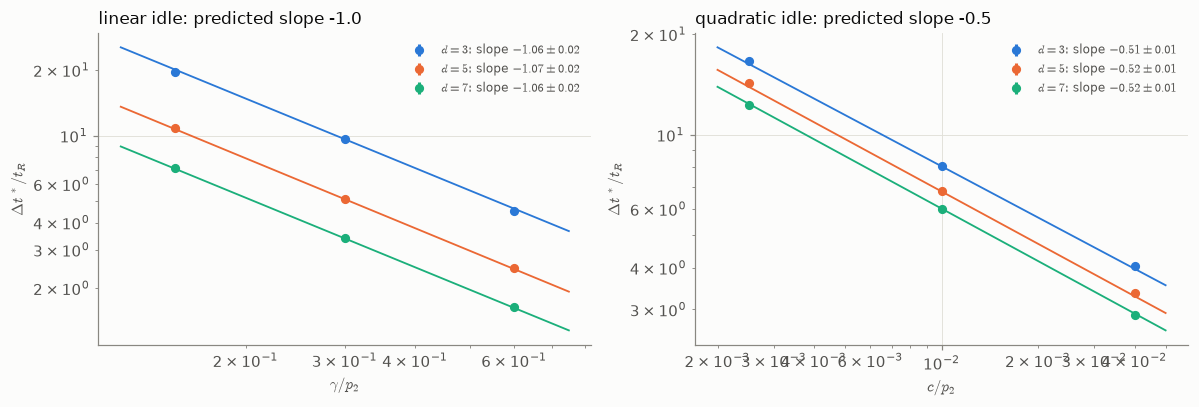

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, fam, xlab, pred in ((axes[0], "lin", r"$\gamma / p_2$", -1.0), (axes[1], "quad", r"$c / p_2$", -0.5)):
    for r in isc["rows"]:
        cs = [c for c in r["curves"] if c["family"] == fam]
        x = np.array([c["value"] for c in cs]); y = np.array([c["optimum"]["dt_star"] for c in cs])
        lo = y - np.array([c["optimum"]["lo"] for c in cs]); hi = np.array([c["optimum"]["hi"] for c in cs]) - y
        ax.errorbar(x, y, yerr=[lo, hi], fmt="o", color=P.D_COLOR[r["d"]], ms=5,
                    label=rf"$d = {r['d']}$: slope ${r['slopes'][fam]['slope']:.2f} \pm {r['slopes'][fam]['se']:.2f}$")
        m = r["slopes"][fam]["slope"]; xs = np.geomspace(x.min() * 0.8, x.max() * 1.25, 20)
        ax.plot(xs, y[1] * (xs / x[1]) ** m, "-", color=P.D_COLOR[r["d"]], lw=1.2)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.legend(fontsize=8)
    ax.set_xlabel(xlab); ax.set_ylabel(r"$\Delta t^* / t_R$")
    ax.set_title(f"{'linear' if fam == 'lin' else 'quadratic'} idle: predicted slope {pred}", loc="left")
fig.tight_layout()
P.save(fig, "08b_dt_star_vs_idle_strength_1")

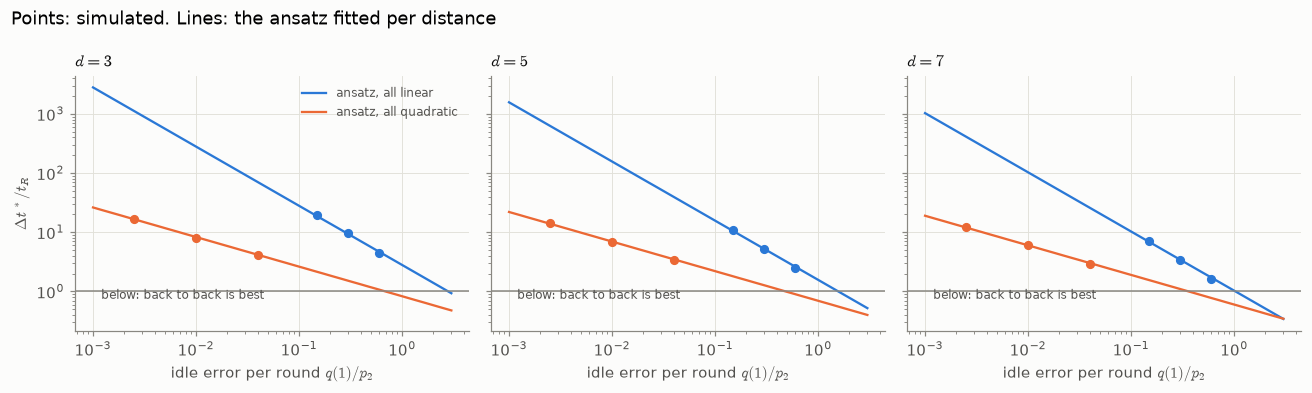

In [4]:
fig, axes = plt.subplots(1, len(isc["rows"]), figsize=(4 * len(isc["rows"]), 3.6), sharey=True)
for ax, r in zip(np.atleast_1d(axes), isc["rows"]):
    for fam, col in (("lin", P.SERIES[0]), ("quad", P.SERIES[1])):
        F = r["formula"][fam]
        ax.plot([q["q_over_p2"] for q in F], [q["dt_star"] for q in F], "-", color=col, lw=1.5,
                label=f"ansatz, all {'linear' if fam == 'lin' else 'quadratic'}")
        cs = [c for c in r["curves"] if c["family"] == fam]
        q1 = [(c["value"] if fam == "lin" else np.sin(np.sqrt(c["value"] * 5e-3)) ** 2 / 5e-3) for c in cs]
        ax.plot(q1, [c["optimum"]["dt_star"] for c in cs], "o", color=col, ms=5)
    ax.axhline(1, color=P.MUTED, lw=1); ax.text(1.2e-3, 0.75, "below: back to back is best", color=P.INK_2, fontsize=8)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(P.dl(r["d"]), loc="left")
    ax.set_xlabel(r"idle error per round $q(1) / p_2$")
np.atleast_1d(axes)[0].set_ylabel(r"$\Delta t^* / t_R$"); np.atleast_1d(axes)[0].legend(fontsize=8)
fig.suptitle("Points: simulated. Lines: the ansatz fitted per distance", x=0.01, ha="left")
fig.tight_layout()
P.save(fig, "08b_dt_star_vs_idle_strength_2")

**Reading.**
- *Measured:* Δt* follows the power laws the ansatz implies, γ⁻¹ for linear idle and c^(−1/2) for
  quadratic, at every distance (original notebook 07: −1.06…−1.07 and −0.51…−0.52).
- *Measured:* the fitted α corresponds to g below the paper's 0.8 at these small distances
  (as in the scaling study, notebook 03).
- *Interp.:* the crossing of the lines with Δt* = 1 is the boundary of the useful regime, in
  units of idle error per round over p2: waiting pays only when idling per round is well below
  the two-qubit gate error. Notebook 08 places H2 on this axis through the round duration t_R.

## Where waiting pays, over the whole idle plane (figure 07c, revised)

The calibrated ansatz's Δt* over the plane of linear and quadratic idle strength, per distance.
Inside the dashed box simulations exist (the six fitted curves sit on its edges); outside it
the formula is extrapolated (pale). The white line is Δt* = 1: beyond it, back to back is best.
The star is a simulation with **both** idle terms that was held out of the fit, the test of
the formula. The dark line is H2-1E's emulator idle rates for round durations t_R from 1 to
300 ms: the device's position in this plane is set by t_R (γ/p2 ∝ t_R, c/p2 ∝ t_R²).

*Assumption:* the axes are idle strength relative to p2, so the map built at scaled gates
(p2 = 5×10⁻³) is read at H2's own p2; notebook 07 of the original repo checked that halving
all rates leaves Δt* unchanged.

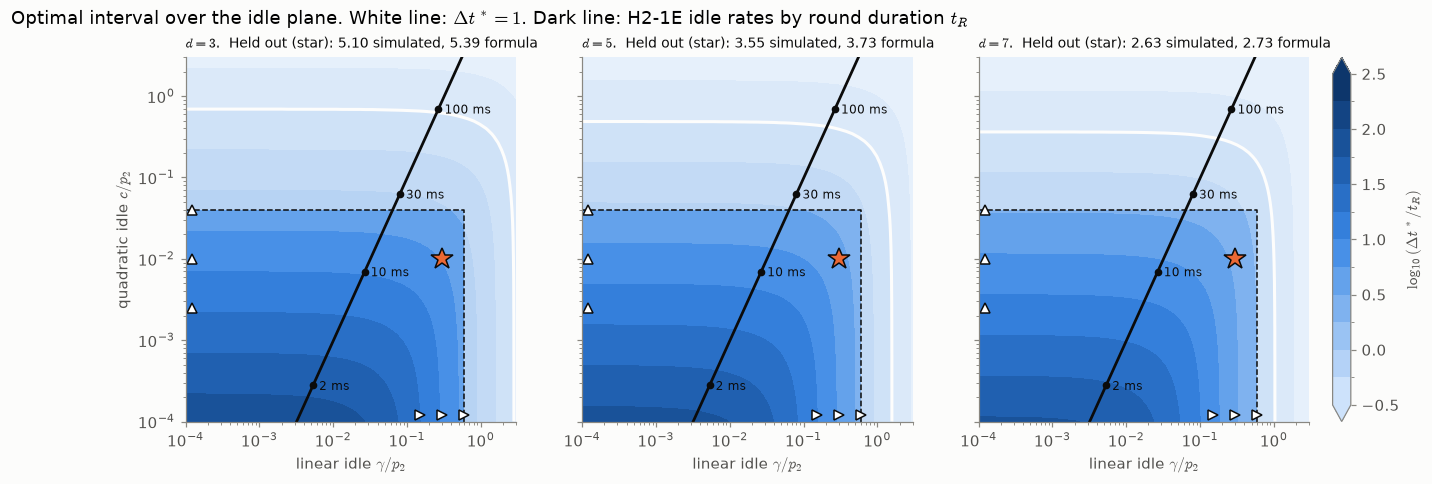

In [5]:
import math
from matplotlib.colors import BoundaryNorm
cal = json.loads((Path("..") / "config" / "h2_1e_emulator.json").read_text())
omega = 2 * math.pi * cal["quad_rate"] * cal["quad_factor"]          # "cycles" reading
tR = np.geomspace(1e-3, 0.3, 60)
h2_g = cal["gamma"] * tR / cal["p2"]; h2_c = (omega * tR / 2) ** 2 / cal["p2"]
fig, axes = plt.subplots(1, len(isc["rows"]), figsize=(4.6 * len(isc["rows"]), 4.3), sharey=True)
levels = np.arange(-0.5, 2.51, 0.25)
cmap = P.sequential_cmap(); norm = BoundaryNorm(levels, cmap.N)
lin, quad = isc["setup"]["lin"], isc["setup"]["quad"]
for ax, r in zip(np.atleast_1d(axes), isc["rows"]):
    ax_ = np.array(r["map"]["axis"]); Z = np.log10(np.array(r["map"]["dt_star"]))
    cs = ax.contourf(ax_, ax_, Z, levels=levels, cmap=cmap, norm=norm, extend="both")
    ax.contour(ax_, ax_, Z, levels=[0.0], colors="white", linewidths=2)
    # extrapolated region: everything outside the simulated box
    box = (min(lin), max(lin), min(quad), max(quad))
    from matplotlib.patches import Rectangle
    for x0, y0, x1, y1 in ((box[1], ax_[0], ax_[-1], ax_[-1]), (ax_[0], box[3], box[1], ax_[-1])):
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, color=P.SURFACE, alpha=0.55, lw=0, zorder=2))
    ax.plot([ax_[0], box[1], box[1]], [box[3], box[3], ax_[0]], "--", color=P.INK, lw=1)
    ax.plot(lin, [ax_[1]] * 3, ">", color="white", mec=P.INK, ms=7)
    ax.plot([ax_[1]] * 3, quad, "^", color="white", mec=P.INK, ms=7)
    h = r["held_out"]
    ax.plot(h["gamma_over_p2"], h["c_over_p2"], "*", color=P.SERIES[1], mec=P.INK, ms=15)

    ax.plot(h2_g, h2_c, "-", color=P.INK, lw=1.8)
    for t in (2e-3, 1e-2, 3e-2, 0.1, 0.3):
        g_, c_ = cal["gamma"] * t / cal["p2"], (omega * t / 2) ** 2 / cal["p2"]
        if g_ > ax_[0] and c_ > ax_[0]:
            ax.plot(g_, c_, "o", color=P.INK, ms=4)
            ax.annotate(f"{t*1e3:g} ms", (g_, c_), xytext=(4, -3), textcoords="offset points", fontsize=8, color=P.INK)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(False)
    ax.set_xlim(ax_[0], ax_[-1]); ax.set_ylim(ax_[0], ax_[-1])
    ax.set_xlabel(r"linear idle $\gamma / p_2$")
    ax.set_title(rf"$d = {r['d']}$.  Held out (star): {h['optimum']['dt_star']:.2f} simulated, {h['formula_dt_star']:.2f} formula",
                 loc="left", fontsize=9)
np.atleast_1d(axes)[0].set_ylabel(r"quadratic idle $c / p_2$")
fig.colorbar(cs, ax=axes, label=r"$\log_{10}(\Delta t^* / t_R)$", fraction=0.025, pad=0.02)
fig.suptitle(r"Optimal interval over the idle plane. White line: $\Delta t^* = 1$. Dark line: H2-1E idle rates by round duration $t_R$", x=0.01, ha="left")
P.save(fig, "08b_dt_star_vs_idle_strength_3")

**Reading.**
- *Measured:* the held-out simulation (both idle terms at once) is predicted to within 4–6%
  (Δt* 5.10, 3.55, 2.63 simulated against 5.39, 3.73, 2.73 at d = 3, 5, 7), with the formula
  slightly long; inside the box the map is a calibrated prediction, not just a fit.
- *Interp.:* the white line is the regime boundary in idle-noise space. H2-1E's trajectory
  crosses it at a round duration of tens of ms, consistent with the full-circuit simulations
  at H2's own rates (notebook 08), from a different route: a fitted formula at scaled gates.
- *Limits:* outside the box (pale) the formula is extrapolated; the quadratic search stops at
  the term's first maximum, where the twirled model stops describing decoherence.